# Pillbox wakefield mesh-convergence study

This notebook compares the mesh convergence of the standard WAKIS cavity geometry for

- **legacy** STL discretization,
- **conformal** STL discretization with PEC snapping,
- optionally **CST Wakefield Solver** data imported from parameter sweeps.

The convergence quantity is not the full impedance curve. Instead, the first two
longitudinal resonance frequencies below \(1\,\mathrm{GHz}\) are extracted with the
same **Smart Bound Determination** used in `001_Wakefield-simulation.ipynb`.

For every requested number of mesh cells per vacuum wavelength,

\[
h_\mathrm{target}=\frac{\lambda_\mathrm{ref}}{N_\mathrm{pWl}},
\qquad
\lambda_\mathrm{ref}=\frac{c}{f_\mathrm{max}},
\]

the Cartesian mesh numbers \(N_x,N_y,N_z\) are calculated from the physical domain
dimensions. The same mesh is then used for the legacy and conformal WAKIS runs.

The WAKIS settings used throughout are

- `cfln = 0.4`,
- `conformal_pec_snap_fraction = 0.2`,
- vacuum cavity,
- PEC shell,
- PEC background,
- \(f_\mathrm{max}=1\,\mathrm{GHz}\).


In [1]:
from pathlib import Path
import gc

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
from scipy.constants import c

from wakis import GridFIT3D, SolverFIT3D, WakeSolver

%matplotlib widget

pv.set_jupyter_backend("static")

## Geometry and simulation settings

The STL paths are the same as in the preceding legacy/conformal pillbox examples.

`NPWL_VALUES` is the sweep parameter. Because \(N_x,N_y,N_z\) are integer-valued,
the actually obtained worst-direction resolution can be slightly higher than the
requested value. Both values are stored.

The physical wake-integration exclusion length is kept approximately constant as the
mesh is refined. The reference corresponds to the previous setting `skip_cells=5`
for `Nz=60`.


In [16]:
# ---------------------------------------------------------------------------
# Geometry
# ---------------------------------------------------------------------------

cavity_path = Path("../tests/stl/007_vacuum_cavity.stl")
shell_path = Path("../tests/stl/007_lossymetal_shell.stl")

stl_solids = {
    "cavity": str(cavity_path),
    "shell": str(shell_path),
}

stl_materials = {
    "cavity": "vacuum",
    "shell": "pec",
}

stl_material_types = {
    "cavity": "normal",
    "shell": "pec",
}

solids = pv.read(cavity_path) + pv.read(shell_path)
xmin, xmax, ymin, ymax, zmin, zmax = solids.bounds

Lx = xmax - xmin
Ly = ymax - ymin
Lz = zmax - zmin

# ---------------------------------------------------------------------------
# Mesh-convergence settings
# ---------------------------------------------------------------------------

FMAX = 1.0e9
REFERENCE_WAVELENGTH = c / FMAX

NPWL_VALUES = [
    8,
    10,
    12,
    15,
    20,
    25,
    30,
]

# NPWL_VALUES = [
#     8,
#     10,
#     12,
# ]

# ---------------------------------------------------------------------------
# WAKIS settings
# ---------------------------------------------------------------------------

CFLN = 0.15
CONFORMAL_ETA = 0.1

sigmaz = 10.0e-2
q = 1.0e-9
beta = 1.0

xsource = 0.0
ysource = 0.0
xtest = 0.0
ytest = 0.0

wakelength = 100.0

# Keep approximately the same physical exclusion length used previously:
# skip_cells = 5 for Nz = 60.
SKIP_DISTANCE = Lz * (5.0 / 60.0)

bc_low = ["pec", "pec", "pec"]
bc_high = ["pec", "pec", "pec"]

dtype = np.float32

# Recompute the longitudinal impedance on the same frequency axis for all runs.
IMPEDANCE_SAMPLES = 4001

# ---------------------------------------------------------------------------
# Smart-Bound settings
# ---------------------------------------------------------------------------

N_EXPECTED_RESONANCES = 2
SMART_FMIN = 10.0e6
SMART_PEAK_HEIGHT_FRACTION = 0.01
SMART_MIN_PEAK_DISTANCE_HZ = 30.0e6

# Same resonator-bound scalings used in 001_Wakefield-simulation.ipynb.
SMART_RS_BOUNDS = [0.8, 10.0]
SMART_Q_BOUNDS = [0.5, 5.0]
SMART_FRES_BOUNDS = [-0.01e9, +0.01e9]

# ---------------------------------------------------------------------------
# Execution / caching
# ---------------------------------------------------------------------------

RUN_WAKIS = True
OVERWRITE_WAKIS_CACHE = False

results_root = Path("_pillbox_mesh_convergence")
results_root.mkdir(exist_ok=True)

print("Domain dimensions:")
print(f"  Lx = {Lx:.6g} m")
print(f"  Ly = {Ly:.6g} m")
print(f"  Lz = {Lz:.6g} m")
print()
print(f"fmax                 = {FMAX / 1e9:.3f} GHz")
print(f"reference wavelength = {REFERENCE_WAVELENGTH:.6g} m")
print(f"cfln                 = {CFLN}")
print(f"conformal eta        = {CONFORMAL_ETA}")
print(f"wakelength           = {wakelength:.3f} m")

Domain dimensions:
  Lx = 0.52 m
  Ly = 0.52 m
  Lz = 0.8 m

fmax                 = 1.000 GHz
reference wavelength = 0.299792 m
cfln                 = 0.15
conformal eta        = 0.1
wakelength           = 100.000 m


## Meshes generated from \(N_\mathrm{pWl}\)

The target spacing is applied independently to all three domain dimensions:

\[
N_x=\left\lceil \frac{L_x}{h_\mathrm{target}}\right\rceil,\qquad
N_y=\left\lceil \frac{L_y}{h_\mathrm{target}}\right\rceil,\qquad
N_z=\left\lceil \frac{L_z}{h_\mathrm{target}}\right\rceil.
\]

The reported `actual NpWl` is based on the largest of
\(\Delta x,\Delta y,\Delta z\).


In [17]:
mesh_table = []

print(
    f"{'requested':>10s} "
    f"{'Nx':>6s} {'Ny':>6s} {'Nz':>6s} "
    f"{'actual':>10s} "
    f"{'dx [mm]':>10s} {'dy [mm]':>10s} {'dz [mm]':>10s}"
)
print("-" * 82)

for npwl in NPWL_VALUES:
    target_h = REFERENCE_WAVELENGTH / npwl

    Nx = max(1, int(np.ceil(Lx / target_h)))
    Ny = max(1, int(np.ceil(Ly / target_h)))
    Nz = max(1, int(np.ceil(Lz / target_h)))

    dx = Lx / Nx
    dy = Ly / Ny
    dz = Lz / Nz

    actual_npwl = REFERENCE_WAVELENGTH / max(dx, dy, dz)

    mesh_table.append(
        {
            "requested_npwl": float(npwl),
            "actual_npwl": float(actual_npwl),
            "Nx": Nx,
            "Ny": Ny,
            "Nz": Nz,
            "dx": dx,
            "dy": dy,
            "dz": dz,
        }
    )

    print(
        f"{npwl:10.2f} "
        f"{Nx:6d} {Ny:6d} {Nz:6d} "
        f"{actual_npwl:10.3f} "
        f"{dx * 1e3:10.3f} "
        f"{dy * 1e3:10.3f} "
        f"{dz * 1e3:10.3f}"
    )

 requested     Nx     Ny     Nz     actual    dx [mm]    dy [mm]    dz [mm]
----------------------------------------------------------------------------------
      8.00     14     14     22      8.071     37.143     37.143     36.364
     10.00     18     18     27     10.118     28.889     28.889     29.630
     12.00     21     21     33     12.107     24.762     24.762     24.242
     15.00     27     27     41     15.364     19.259     19.259     19.512
     20.00     35     35     54     20.178     14.857     14.857     14.815
     25.00     44     44     67     25.108     11.818     11.818     11.940
     30.00     53     53     81     30.354      9.811      9.811      9.877


In [18]:
Nx, Ny, Nz = 20, 20, 30

grid = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    geometry_mode="conformal",
    bg_material_type="normal",
    conformal_pec_snap_fraction=0.2,
    stl_method="interior_points",
    verbose=1,
)


# boundary conditions
bc_low = ["pec", "pec", "pec"]
bc_high = ["pec", "pec", "pec"]

solver = SolverFIT3D(
    grid,
    bc_low=bc_low,
    bc_high=bc_high,
    use_stl=True,
    bg=[1.0, 1.0],
    verbose=1,
)

Generating grid with 12000 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 2931 primal points, 2655 cell centers, and 2885 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 1347 primal points, 618 cell centers, and 1448 dual points marked inside the solid.
    * primal x-edges: 1326 geometric hits, 1326 crossings, 0 contacts, 0 with multiple crossing positions
    * primal y-edges: 1327 geometric hits, 1327 crossings, 0 contacts, 0 with multiple crossing positions
    * primal z-edges: 1058 geometric hits, 1058 crossings, 0 contacts, 0 with multiple crossing positions
    * dual x-edges: 1260 geometric hits, 1260 crossings, 0 contacts, 0 with multiple crossing positions
    * dual y-edges: 1260 geometric hits, 1260 crossings, 0 contacts, 0 with multiple crossing positions
    * dual z-edges: 1064 geometric hits, 1064 crossings, 0 contacts, 0 with multiple cross

/home/hschreib/Documents/Wakis/WAKIS/wakis/gridFIT3D.py:4434: UserWarning: Conformal geometry diagnostics:
31 endpoint interface edges have no geometric crossing and will not receive a conformal correction.
2629 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
  self._warn_interface_diagnostics()


    * primal x-faces: 1733 candidates, 1709 segments, 1706 resolved splits
    * primal y-faces: 1729 candidates, 1709 segments, 1704 resolved splits
    * primal z-faces: 1912 candidates, 1912 segments, 1912 resolved splits
    * dual x-faces: 1767 candidates, 1757 segments, 1751 resolved splits
    * dual y-faces: 1764 candidates, 1750 segments, 1746 resolved splits
    * dual z-faces: 1960 candidates, 1960 segments, 1954 resolved splits
Total grid initialization time: 6.523881912231445 s
Initializing Electromagnetic solver...
Assembling operator matrices...
Applying boundary conditions...
Adding material tensors...
Calculating maximal stable timestep...
Pre-computing...
Using MKL backend for time-stepping...
Total solver initialization time: 0.24713993072509766 s


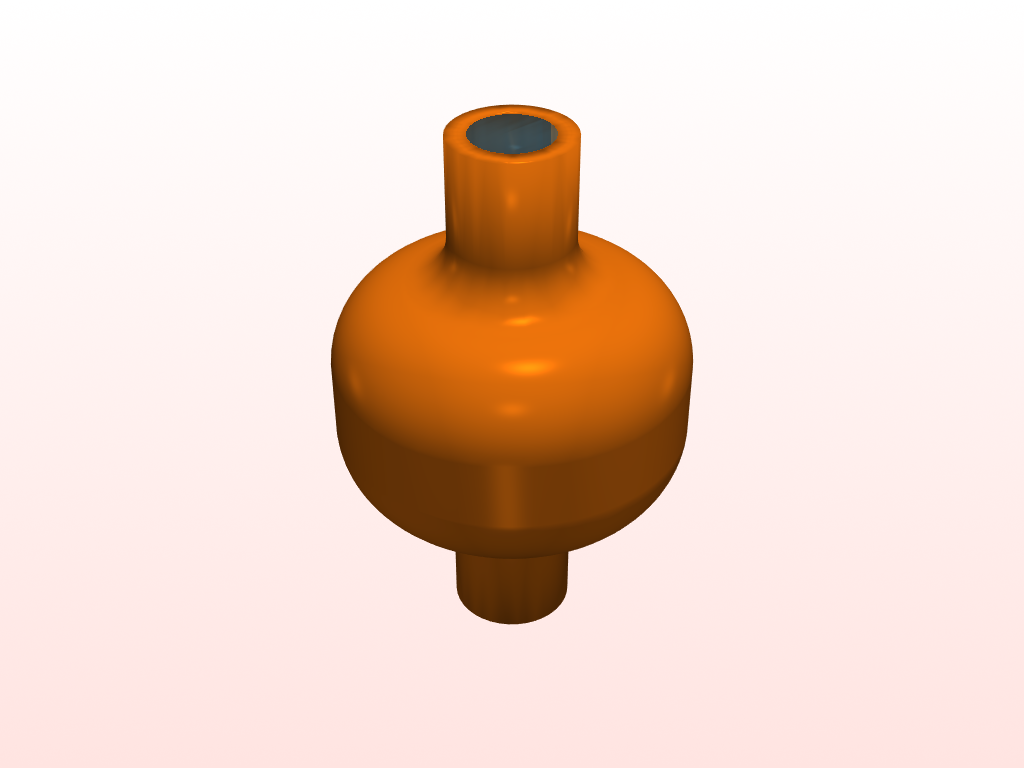

In [7]:
pl = pv.Plotter()
pl.add_mesh(pv.read(shell_path), color="tab:orange", specular=0.5, smooth_shading=True)
pl.add_mesh(
    pv.read(cavity_path),
    color="tab:blue",
    opacity=0.5,
    specular=0.5,
    smooth_shading=True,
)
pl.set_background("mistyrose", top="white")
pl.show()

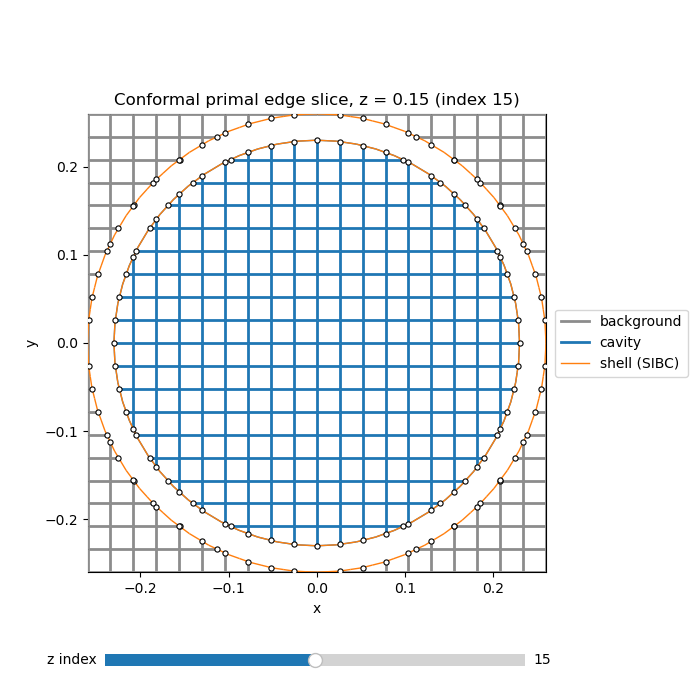

In [8]:
ax = solver.plot_conformal_primal_edge_slice(
    normal="z",
    # index=slice_index,
    show_full_grid=False,
    show_stl=True,
    show_intersection_marker=True,
)

plt.show()

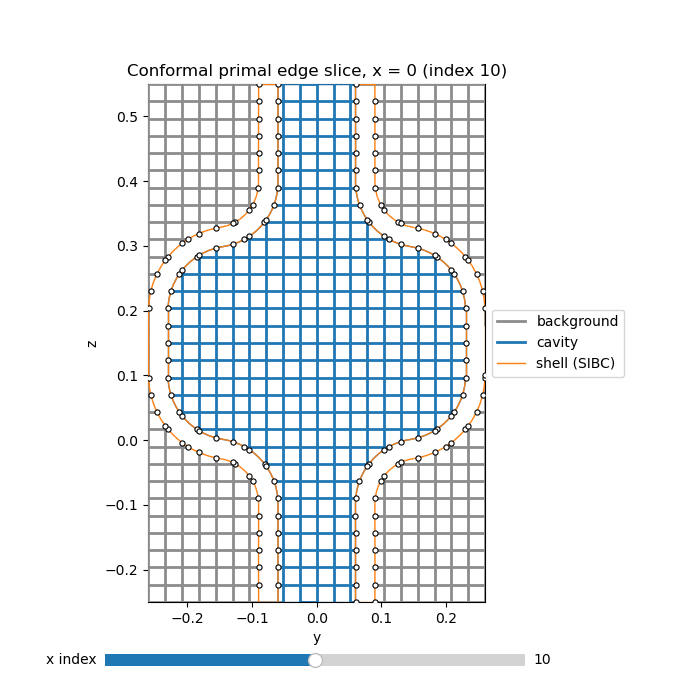

In [9]:
ax = solver.plot_conformal_primal_edge_slice(
    normal="x",
    # index=slice_index,
    show_full_grid=False,
    show_stl=True,
    show_intersection_marker=True,
)

plt.show()

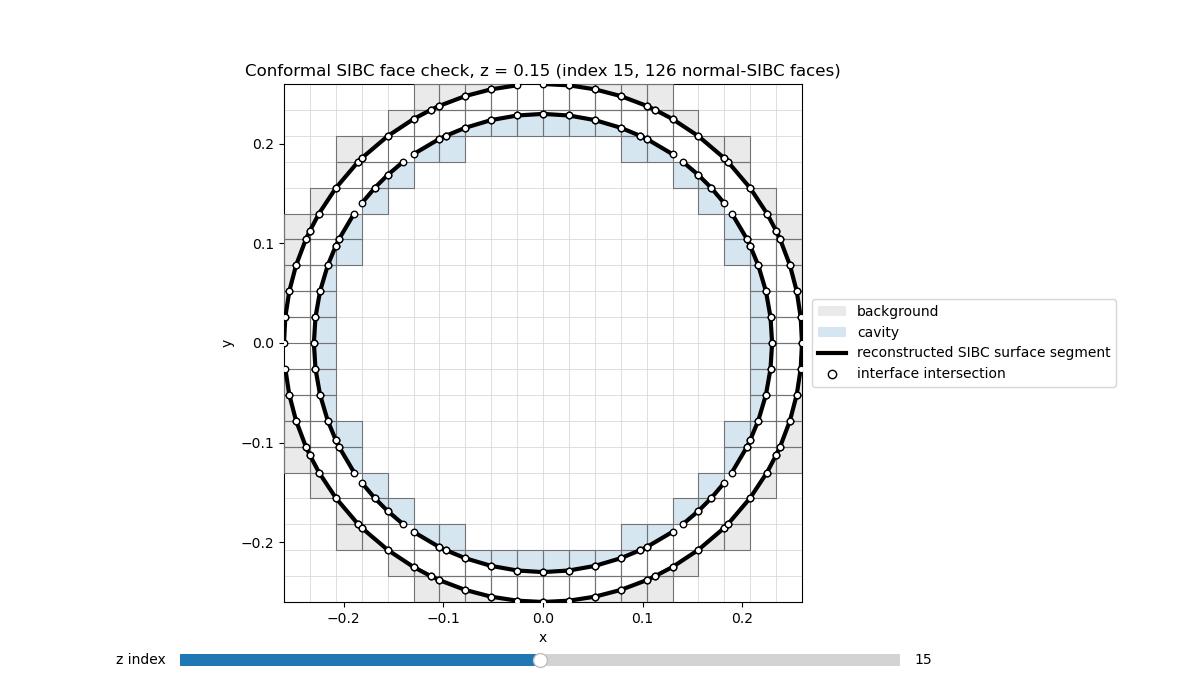

In [8]:
ax = solver.plot_conformal_sibc_slice(normal="z", show_stl=False)

plt.show()

## Resonance extraction with Smart Bound Determination

`WakeSolver.get_SmartBounds()` is used in the same way as in
`001_Wakefield-simulation.ipynb`, but `inspect_bounds=False` is used because this
notebook performs many automatic runs.

For each Smart-Bound resonance interval, the local maximum of
\(|Z_\parallel|\) is found. A three-point parabolic interpolation is then applied
around the discrete maximum to reduce the visible dependence on the impedance
frequency sampling.

If Smart Bounds identifies more than two candidates, the two strongest peaks below
\(1\,\mathrm{GHz}\) are retained and then sorted by frequency. If fewer than two
candidates are found, the extraction raises an error instead of silently assigning
the wrong mode.


In [19]:
def quadratic_peak_frequency(frequencies, magnitudes, peak_index):
    """Refine one sampled maximum with a local three-point parabola."""
    if peak_index <= 0 or peak_index >= len(frequencies) - 1:
        return float(frequencies[peak_index])

    x = frequencies[peak_index - 1 : peak_index + 2]
    y = magnitudes[peak_index - 1 : peak_index + 2]

    x0 = x[1]
    local_x = x - x0

    a, b, _ = np.polyfit(local_x, y, 2)

    if not np.isfinite(a) or not np.isfinite(b) or a >= 0.0:
        return float(frequencies[peak_index])

    offset = -b / (2.0 * a)

    if offset < local_x[0] or offset > local_x[-1]:
        return float(frequencies[peak_index])

    return float(x0 + offset)


def extract_resonances_with_smart_bounds(
    smart_bound_owner,
    frequencies,
    impedance,
    label="",
):
    """Return the two strongest Smart-Bound resonances below FMAX."""
    frequencies = np.asarray(frequencies, dtype=float)
    impedance = np.asarray(impedance)

    finite = (
        np.isfinite(frequencies)
        & np.isfinite(np.abs(impedance))
        & (frequencies >= SMART_FMIN)
        & (frequencies <= FMAX)
    )

    f = frequencies[finite]
    z = impedance[finite]

    if f.size < 3:
        raise RuntimeError(
            f"{label}: fewer than three finite impedance samples in the "
            "requested frequency interval."
        )

    order = np.argsort(f)
    f = f[order]
    z = z[order]

    magnitude = np.abs(z)

    peak_height = SMART_PEAK_HEIGHT_FRACTION * np.max(magnitude)
    df = np.median(np.diff(f))

    distance = max(
        1,
        int(np.round(SMART_MIN_PEAK_DISTANCE_HZ / df)),
    )

    bounds = smart_bound_owner.get_SmartBounds(
        freq_data=f,
        impedance_data=z,
        minimum_peak_height=peak_height,
        distance=distance,
        inspect_bounds=False,
        Rs_bounds=SMART_RS_BOUNDS,
        Q_bounds=SMART_Q_BOUNDS,
        fres_bounds=SMART_FRES_BOUNDS,
    )

    parameter_bounds = list(bounds.parameterBounds)
    n_resonators = int(bounds.N_resonators)

    if len(parameter_bounds) < 3 * n_resonators:
        raise RuntimeError(
            f"{label}: Smart Bounds returned an unexpected parameter-bound layout."
        )

    candidates = []

    for resonator_index in range(n_resonators):
        frequency_bound = parameter_bounds[3 * resonator_index + 2]

        lower = float(frequency_bound[0])
        upper = float(frequency_bound[1])

        local = (f >= max(lower, SMART_FMIN)) & (f <= min(upper, FMAX))

        local_indices = np.flatnonzero(local)

        if local_indices.size == 0:
            continue

        local_peak_index = local_indices[np.argmax(magnitude[local_indices])]

        refined_frequency = quadratic_peak_frequency(
            f,
            magnitude,
            local_peak_index,
        )

        candidates.append(
            {
                "frequency": refined_frequency,
                "height": float(magnitude[local_peak_index]),
                "lower_bound": lower,
                "upper_bound": upper,
            }
        )

    if len(candidates) < N_EXPECTED_RESONANCES:
        raise RuntimeError(
            f"{label}: Smart Bounds found only {len(candidates)} usable "
            f"resonance candidates below {FMAX / 1e9:.3f} GHz; "
            f"{N_EXPECTED_RESONANCES} are required."
        )

    if len(candidates) != N_EXPECTED_RESONANCES:
        print(
            f"[!] {label}: Smart Bounds found {len(candidates)} candidates. "
            f"Using the {N_EXPECTED_RESONANCES} strongest."
        )

    selected = sorted(
        candidates,
        key=lambda item: item["height"],
        reverse=True,
    )[:N_EXPECTED_RESONANCES]

    selected = sorted(
        selected,
        key=lambda item: item["frequency"],
    )

    resonance_frequencies = np.asarray(
        [item["frequency"] for item in selected],
        dtype=float,
    )

    return resonance_frequencies, candidates


def load_cst_impedance(
    path,
    frequency_scale,
    columns,
    delimiter=None,
    skip_header=0,
):
    """
    Load a CST impedance export.

    columns = (frequency, abs_Z) for |Z|,
    or columns = (frequency, Re_Z, Im_Z) for complex impedance.
    """
    data = np.genfromtxt(
        path,
        delimiter=delimiter,
        skip_header=skip_header,
        comments="#",
        invalid_raise=False,
    )

    data = np.atleast_2d(data)

    if len(columns) == 2:
        impedance = data[:, columns[1]].astype(complex)
    elif len(columns) == 3:
        impedance = data[:, columns[1]] + 1j * data[:, columns[2]]
    else:
        raise ValueError("CST_COLUMNS must contain either 2 or 3 column indices.")

    frequency = data[:, columns[0]] * frequency_scale

    finite = np.isfinite(frequency) & np.isfinite(np.abs(impedance))

    return frequency[finite], impedance[finite]

## WAKIS convergence sweep

For each mesh, the **same** \(N_x,N_y,N_z\), beam parameters, wake length,
frequency post-processing and `cfln=0.4` are used for legacy and conformal.

Only the geometry treatment differs:

- legacy: `geometry_mode="legacy"`,
- conformal: `geometry_mode="conformal"`,
  `bg_material_type="pec"`,
  `conformal_pec_snap_fraction=0.2`.

The solver background is `bg="pec"` in both cases.

Each completed impedance curve is cached as a compressed `.npz` file. This makes it
possible to rerun the plotting/post-processing cells without repeating all wakefield
simulations. Temporary `Ez.h5` files are removed after successful post-processing.


In [20]:
wakis_results = {
    "legacy": [],
    "conformal": [],
}

for mesh in mesh_table:
    npwl = mesh["requested_npwl"]
    Nx = mesh["Nx"]
    Ny = mesh["Ny"]
    Nz = mesh["Nz"]

    skip_cells = max(
        1,
        int(np.round(SKIP_DISTANCE / mesh["dz"])),
    )

    print()
    print("#" * 88)
    print(
        f"NpWl={npwl:g}: "
        f"Nx={Nx}, Ny={Ny}, Nz={Nz}, "
        f"actual NpWl={mesh['actual_npwl']:.3f}, "
        f"skip_cells={skip_cells}"
    )
    print("#" * 88)

    for geometry_mode in ("legacy", "conformal"):
        label = f"{geometry_mode}, NpWl={npwl:g}"

        cache_file = results_root / f"wakis_{geometry_mode}_NpWl_{npwl:g}.npz"

        if cache_file.exists() and not OVERWRITE_WAKIS_CACHE:
            cached = np.load(
                cache_file,
                allow_pickle=False,
            )

            frequencies = cached["frequency"]
            impedance = cached["impedance"]
            resonance_frequencies = cached["resonance_frequencies"]
            dt = float(cached["dt"])

            print(f"{label}: loaded cache ({cache_file.name})")

        else:
            if not RUN_WAKIS:
                raise FileNotFoundError(
                    f"No cached result exists for {label}, but RUN_WAKIS is False."
                )

            case_folder = results_root / f"{geometry_mode}_NpWl_{npwl:g}"
            case_folder.mkdir(
                parents=True,
                exist_ok=True,
            )

            ez_file = case_folder / "Ez.h5"

            if ez_file.exists():
                ez_file.unlink()

            grid_kwargs = dict(
                xmin=xmin,
                xmax=xmax,
                ymin=ymin,
                ymax=ymax,
                zmin=zmin,
                zmax=zmax,
                Nx=Nx,
                Ny=Ny,
                Nz=Nz,
                stl_solids=stl_solids,
                stl_materials=stl_materials,
                stl_material_types=stl_material_types,
                stl_method="voxelize_rectilinear",
                geometry_mode=geometry_mode,
                subpixel_smoothing=False,
                stl_scale=1.0,
                stl_rotate=[0.0, 0.0, 0.0],
                stl_translate=[0.0, 0.0, 0.0],
                verbose=1,
            )

            if geometry_mode == "conformal":
                grid_kwargs["bg_material_type"] = "pec"
                grid_kwargs["conformal_pec_snap_fraction"] = CONFORMAL_ETA

            grid = GridFIT3D(**grid_kwargs)

            wake = WakeSolver(
                wakelength=wakelength,
                q=q,
                sigmaz=sigmaz,
                beta=beta,
                xsource=xsource,
                ysource=ysource,
                xtest=xtest,
                ytest=ytest,
                save=False,
                Ez_file=str(ez_file),
                skip_cells=skip_cells,
                verbose=1,
            )

            solver = SolverFIT3D(
                grid,
                wake,
                cfln=CFLN,
                bc_low=bc_low,
                bc_high=bc_high,
                use_stl=True,
                bg="pec",
                dtype=dtype,
                use_gpu=False,
                verbose=1,
            )

            solver.wakesolve(
                wakelength=wakelength,
                save_J=False,
            )

            # Same frequency axis for every WAKIS case.
            wake.calc_long_Z(
                samples=IMPEDANCE_SAMPLES,
                fmax=FMAX,
            )

            frequencies = np.asarray(
                wake.f,
                dtype=float,
            )
            impedance = np.asarray(wake.Z)

            resonance_frequencies, _ = extract_resonances_with_smart_bounds(
                wake,
                frequencies,
                impedance,
                label=label,
            )

            dt = float(solver.dt)

            np.savez_compressed(
                cache_file,
                frequency=frequencies,
                impedance=impedance,
                resonance_frequencies=resonance_frequencies,
                dt=dt,
                requested_npwl=npwl,
                actual_npwl=mesh["actual_npwl"],
                Nx=Nx,
                Ny=Ny,
                Nz=Nz,
                skip_cells=skip_cells,
            )

            if ez_file.exists():
                ez_file.unlink()

            del solver
            del wake
            del grid
            gc.collect()

        wakis_results[geometry_mode].append(
            {
                "requested_npwl": npwl,
                "actual_npwl": mesh["actual_npwl"],
                "Nx": Nx,
                "Ny": Ny,
                "Nz": Nz,
                "skip_cells": skip_cells,
                "dt": dt,
                "frequency": frequencies,
                "impedance": impedance,
                "resonances": resonance_frequencies,
            }
        )

        print(
            f"{label}: "
            f"f1={resonance_frequencies[0] / 1e6:.6f} MHz, "
            f"f2={resonance_frequencies[1] / 1e6:.6f} MHz, "
            f"dt={dt:.6e} s"
        )


########################################################################################
NpWl=8: Nx=14, Ny=14, Nz=22, actual NpWl=8.071, skip_cells=2
########################################################################################
legacy, NpWl=8: loaded cache (wakis_legacy_NpWl_8.npz)
legacy, NpWl=8: f1=485.674394 MHz, f2=674.033230 MHz, dt=1.065301e-11 s
Generating grid with 4312 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 1079 primal points, 960 cell centers, and 1076 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 492 primal points, 32 cell centers, and 492 dual points marked inside the solid.
    * primal x-edges: 652 geometric hits, 652 crossings, 0 contacts, 30 with multiple crossing positions
    * primal y-edges: 654 geometric hits, 654 crossings, 0 contacts, 30 with multiple crossing positions
    * primal z-edges: 490 geometric hits, 48

/home/hschreib/Documents/Wakis/WAKIS/wakis/gridFIT3D.py:4434: UserWarning: Conformal geometry diagnostics:
19 endpoint interface edges have no geometric crossing and will not receive a conformal correction.
262 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
180 edges contain multiple crossing positions. 175 of these are currently used by the conformal discretization; one representative crossing is selected on each edge.
180 edges cross the same STL at more than one distinct position. The geometry on these edges is not fully resolved by the current single-crossing treatment.
  primal x-edge (0, 6, 9): shell
  primal x-edge (13, 6, 9): shell
  primal x-edge (0, 6, 10): shell
  primal x-edge (13, 6, 10): shell
  primal x-edge (0, 6, 11): shell
  ... and 175 more.
  self._warn_interface_diagnostics()


    * primal x-faces: 990 candidates, 852 segments, 844 resolved splits
    * primal y-faces: 988 candidates, 852 segments, 844 resolved splits
    * primal z-faces: 1108 candidates, 904 segments, 904 resolved splits
    * dual x-faces: 971 candidates, 848 segments, 846 resolved splits
    * dual y-faces: 973 candidates, 848 segments, 846 resolved splits
    * dual z-faces: 997 candidates, 767 segments, 766 resolved splits
Total grid initialization time: 2.903195381164551 s
Initializing Wakefield parameters...
Total solver initialization time: 6.0558319091796875e-05 s
Initializing Electromagnetic solver...
Assembling operator matrices...
Applying boundary conditions...
Adding material tensors...
Calculating maximal stable timestep...
Pre-computing...
Using MKL backend for time-stepping...
Total solver initialization time: 0.05659890174865723 s
[!] Beam wavelength spans only 8.2 longitudinal cells; at least 20 are recommended.
Running electromagnetic time-domain simulation...


100%|██████████| 31818/31818 [00:13<00:00, 2334.96it/s]


Reading h5 file _pillbox_mesh_convergence/conformal_NpWl_8/Ez.h5
Size of the h5 file: 0.04 Gb
Calculating longitudinal wake potential WP(s)


...

Elapsed time 183.0355634689331 s
Calculating transverse wake potential WPx, WPy...


100%|██████████| 1065933/1065933 [00:19<00:00, 55526.60it/s]


Elapsed time 19.197243452072144 s
Calculating longitudinal impedance Z...
[!] Using analytic charge distribution λ(s) since no data was provided
Calculating transverse impedance Zx, Zy...
Calculation terminated in 202s
Calculating longitudinal impedance Z...

Calculating bounds using the Smart Bound Determination...

--------------------------------------------------------------------------------
Resonator |   Rs [Ohm/m or Ohm]    |        Q         |        fres [Hz]        
--------------------------------------------------------------------------------
    1     |   376.34 to 4704.24    |  6.69 to 66.87   |  4.35e+07 to 6.35e+07   
    2     |   274.49 to 3431.11    | 94.25 to 942.50  |  3.67e+08 to 3.87e+08   
    3     |   316.95 to 3961.84    |105.56 to 1055.63 |  4.12e+08 to 4.32e+08   
    4     |   632.95 to 7911.83    | 91.70 to 917.00  |  4.48e+08 to 4.68e+08   
    5     |  2979.16 to 37239.51   | 82.83 to 828.33  |  4.87e+08 to 5.07e+08   
    6     | 11981.84 to 149773.05

/home/hschreib/miniforge3/envs/wakis-env/lib/python3.13/site-packages/iddefix/smartBoundDetermination.py:240: RuntimeWarning: divide by zero encountered in scalar divide
  initial_Qs[i] = frequency_data[peak] / (upper_lower_bound * 2)


conformal, NpWl=30: f1=552.636526 MHz, f2=821.133018 MHz, dt=2.840484e-12 s


## WAKIS resonance-convergence table


In [21]:
print(
    f"{'NpWl':>7s} "
    f"{'actual':>8s} "
    f"{'Nx':>5s} {'Ny':>5s} {'Nz':>5s} "
    f"{'legacy f1 [MHz]':>17s} "
    f"{'conf. f1 [MHz]':>17s} "
    f"{'legacy f2 [MHz]':>17s} "
    f"{'conf. f2 [MHz]':>17s}"
)
print("-" * 108)

legacy_by_npwl = {
    result["requested_npwl"]: result for result in wakis_results["legacy"]
}

conformal_by_npwl = {
    result["requested_npwl"]: result for result in wakis_results["conformal"]
}

csv_rows = []

for mesh in mesh_table:
    npwl = mesh["requested_npwl"]

    legacy = legacy_by_npwl[npwl]
    conformal = conformal_by_npwl[npwl]

    print(
        f"{npwl:7.2f} "
        f"{mesh['actual_npwl']:8.3f} "
        f"{mesh['Nx']:5d} "
        f"{mesh['Ny']:5d} "
        f"{mesh['Nz']:5d} "
        f"{legacy['resonances'][0] / 1e6:17.6f} "
        f"{conformal['resonances'][0] / 1e6:17.6f} "
        f"{legacy['resonances'][1] / 1e6:17.6f} "
        f"{conformal['resonances'][1] / 1e6:17.6f}"
    )

    csv_rows.append(
        [
            npwl,
            mesh["actual_npwl"],
            mesh["Nx"],
            mesh["Ny"],
            mesh["Nz"],
            legacy["resonances"][0],
            legacy["resonances"][1],
            conformal["resonances"][0],
            conformal["resonances"][1],
        ]
    )

np.savetxt(
    results_root / "wakis_resonance_convergence.csv",
    np.asarray(csv_rows),
    delimiter=",",
    header=(
        "requested_NpWl,actual_NpWl,Nx,Ny,Nz,"
        "legacy_f1_Hz,legacy_f2_Hz,"
        "conformal_f1_Hz,conformal_f2_Hz"
    ),
    comments="",
)

   NpWl   actual    Nx    Ny    Nz   legacy f1 [MHz]    conf. f1 [MHz]   legacy f2 [MHz]    conf. f2 [MHz]
------------------------------------------------------------------------------------------------------------
   8.00    8.071    14    14    22        485.674394        542.447690        674.033230        816.693795
  10.00   10.118    18    18    27        495.036072        569.835379        688.628609        842.706729
  12.00   12.107    21    21    33        505.652051        564.920663        722.745265        826.579343
  15.00   15.364    27    27    41        513.734014        556.369557        739.015113        826.201477
  20.00   20.178    35    35    54        525.099338        553.038770        760.103404        824.576393
  25.00   25.108    44    44    67        526.201502        551.703469        772.612007        821.757214
  30.00   30.354    53    53    81        532.261287        552.636526        779.152153        821.133018


## WAKIS-only convergence plot

This is useful before CST data are available.


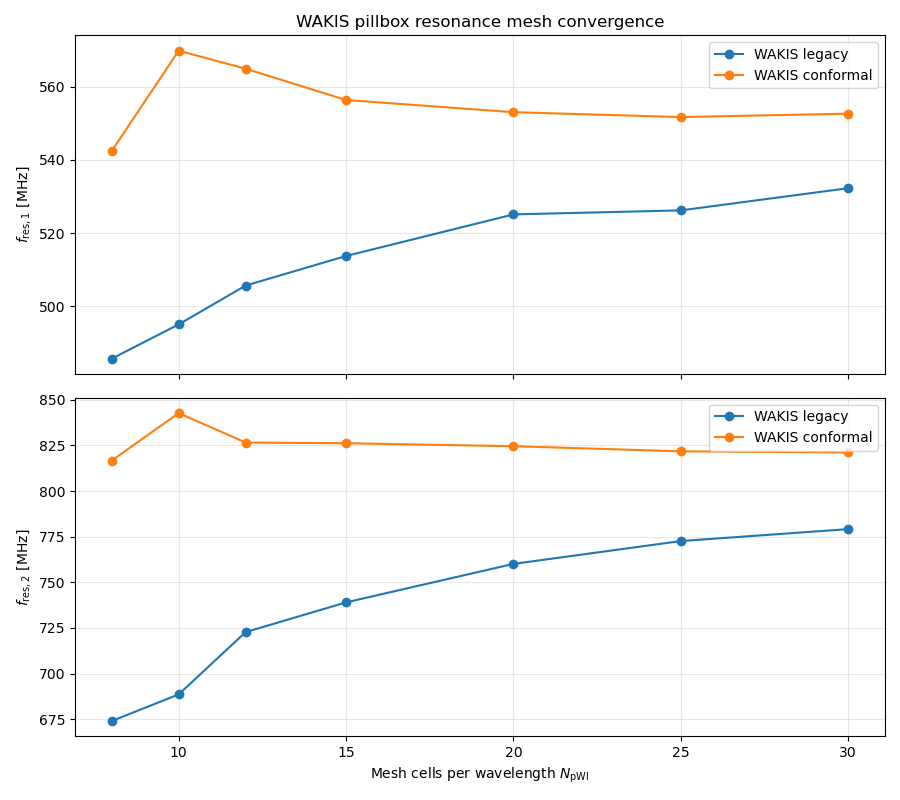

In [22]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(9, 8),
    sharex=True,
)

for mode, label in (
    ("legacy", "WAKIS legacy"),
    ("conformal", "WAKIS conformal"),
):
    npwl = np.asarray([result["requested_npwl"] for result in wakis_results[mode]])

    resonances = np.asarray([result["resonances"] for result in wakis_results[mode]])

    axes[0].plot(
        npwl,
        resonances[:, 0] / 1e6,
        marker="o",
        label=label,
    )

    axes[1].plot(
        npwl,
        resonances[:, 1] / 1e6,
        marker="o",
        label=label,
    )

axes[0].set_ylabel(r"$f_{\mathrm{res},1}$ [MHz]")
axes[1].set_ylabel(r"$f_{\mathrm{res},2}$ [MHz]")
axes[1].set_xlabel(r"Mesh cells per wavelength $N_{\mathrm{pWl}}$")
axes[0].set_title("WAKIS pillbox resonance mesh convergence")

for axis in axes:
    axis.grid(True, alpha=0.3)
    axis.legend()

fig.tight_layout()
plt.show()

## Optional CST parameter-sweep data

Export one longitudinal impedance curve for every CST mesh setting.

Populate `CST_FILES` with the CST `NpWl` value as key and the exported file as value.
For example:

```python
CST_FILES = {
    10: Path("cst/Z_NpWl10.txt"),
    15: Path("cst/Z_NpWl15.txt"),
    20: Path("cst/Z_NpWl20.txt"),
}
```

The default loader assumes:

- frequency in **GHz**,
- column 0: frequency,
- column 1: \(|Z_\parallel|\).

For an export containing frequency, real part and imaginary part, use

```python
CST_COLUMNS = (0, 1, 2)
```

instead.

Change `CST_FREQUENCY_SCALE`, `CST_DELIMITER` or `CST_SKIP_HEADER` if required by
the actual CST text export.


In [23]:
import re
from pathlib import Path

import numpy as np


def load_cst_parameter_sweep(path):
    """
    Load a CST ASCII export containing several parameter-sweep blocks.

    Each block is expected to start with a line such as

        #Parameters = {...; nmesh=5; ...}

    followed by comment/header lines and two numerical columns:

        frequency [Hz]    |Z| [Ohm]

    Returns
    -------
    data : dict
        Dictionary indexed by nmesh:

        data[nmesh]["frequency"]
        data[nmesh]["impedance"]
    """
    path = Path(path)

    data = {}

    current_nmesh = None
    current_frequency = []
    current_impedance = []

    def store_current_block():
        if current_nmesh is None:
            return

        if len(current_frequency) == 0:
            return

        data[current_nmesh] = {
            "frequency": np.asarray(
                current_frequency,
                dtype=float,
            ),
            "impedance": np.asarray(
                current_impedance,
                dtype=float,
            ),
        }

    with path.open(
        "r",
        encoding="utf-8",
        errors="ignore",
    ) as file:
        for line in file:
            line = line.strip()

            # ----------------------------------------------------------
            # Start of a new CST parameter block
            # ----------------------------------------------------------
            if line.startswith("#Parameters"):
                store_current_block()

                current_frequency = []
                current_impedance = []

                match = re.search(
                    r"\bnmesh\s*=\s*([0-9.+\-eE]+)",
                    line,
                )

                if match is None:
                    raise ValueError(
                        f"Found a parameter block without an nmesh value:\n{line}"
                    )

                nmesh_value = float(match.group(1))

                # Use integer keys whenever nmesh is integral.
                if nmesh_value.is_integer():
                    current_nmesh = int(nmesh_value)
                else:
                    current_nmesh = nmesh_value

                continue

            # Ignore empty lines and CST header/comment lines.
            if not line or line.startswith("#") or line.startswith("*"):
                continue

            # ----------------------------------------------------------
            # Numerical data
            # ----------------------------------------------------------
            columns = line.split()

            if len(columns) < 2:
                continue

            try:
                frequency = float(columns[0])
                impedance = float(columns[1])
            except ValueError:
                continue

            if current_nmesh is None:
                continue

            current_frequency.append(frequency)
            current_impedance.append(impedance)

    # Store the last block.
    store_current_block()

    return data


cst_data = load_cst_parameter_sweep("Z_long_CST.txt")

for nmesh, result in cst_data.items():
    print(
        f"nmesh={nmesh}: "
        f"{len(result['frequency'])} samples, "
        f"f=["
        f"{result['frequency'][0] / 1e6:.1f}, "
        f"{result['frequency'][-1] / 1e6:.1f}"
        f"] MHz"
    )

nmesh=5: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=7: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=9: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=11: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=13: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=15: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=8: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=10: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=12: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=20: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=25: 1001 samples, f=[0.0, 1023.9] MHz
nmesh=30: 1001 samples, f=[0.0, 1023.9] MHz


## Extract CST resonances with the same Smart-Bound procedure


In [24]:
cst_data = load_cst_parameter_sweep("Z_long_CST.txt")

cst_results = []

# Only used to access get_SmartBounds().
smart_bound_owner = WakeSolver()

for nmesh, result in sorted(cst_data.items()):
    frequency = result["frequency"]
    impedance = result["impedance"]

    resonance_frequencies, _ = extract_resonances_with_smart_bounds(
        smart_bound_owner,
        frequency,
        impedance,
        label=f"CST, NpWl={nmesh}",
    )

    cst_results.append(
        {
            "requested_npwl": nmesh,
            "frequency": frequency,
            "impedance": impedance,
            "resonances": resonance_frequencies,
        }
    )

    print(
        f"CST NpWl={nmesh}: "
        f"f1={resonance_frequencies[0] / 1e6:.6f} MHz, "
        f"f2={resonance_frequencies[1] / 1e6:.6f} MHz"
    )

Initializing Wakefield parameters...
Total solver initialization time: 0.0008568763732910156 s

Calculating bounds using the Smart Bound Determination...

--------------------------------------------------------------------------------
Resonator |   Rs [Ohm/m or Ohm]    |        Q         |        fres [Hz]        
--------------------------------------------------------------------------------
    1     | 18297.75 to 228721.83  |134.00 to 1340.00 |  5.39e+08 to 5.59e+08   
    2     |   656.54 to 8206.79    |190.25 to 1902.50 |  7.69e+08 to 7.89e+08   
    3     | 22410.64 to 280133.04  |198.00 to 1980.00 |  8.01e+08 to 8.21e+08   
--------------------------------------------------------------------------------
[!] CST, NpWl=5: Smart Bounds found 3 candidates. Using the 2 strongest.
CST NpWl=5: f1=548.604767 MHz, f2=811.035993 MHz

Calculating bounds using the Smart Bound Determination...

--------------------------------------------------------------------------------
Resonator |   R

## Longitudinal impedance comparison at fixed mesh resolution

For one representative mesh resolution, the complete longitudinal impedance
spectrum is compared between WAKIS legacy, WAKIS conformal and CST.

This complements the resonance-frequency convergence study by showing not only
the extracted resonance positions, but the underlying impedance curves from
which they are obtained.

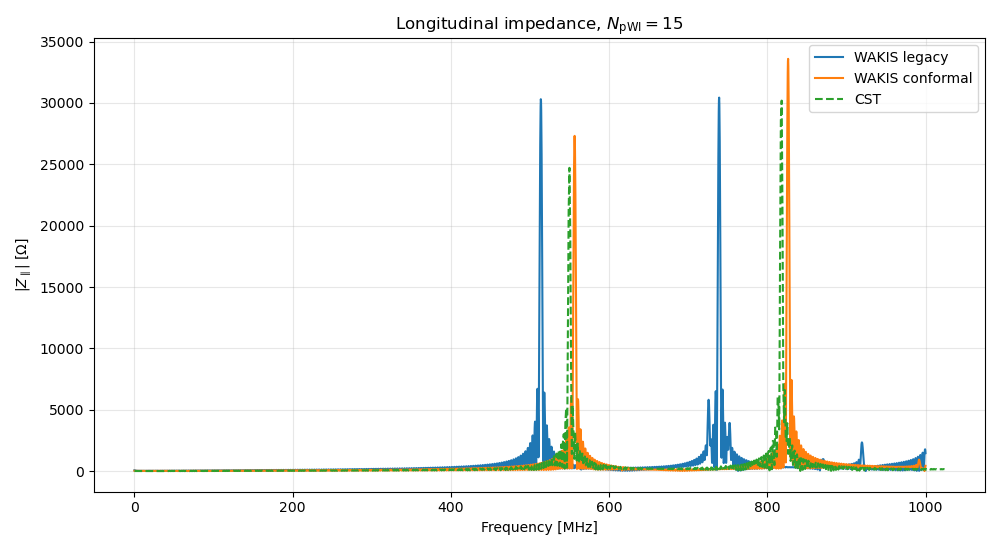

In [25]:
target_NpWl = 15.0

legacy_result = next(
    result
    for result in wakis_results["legacy"]
    if np.isclose(
        result["requested_npwl"],
        target_NpWl,
    )
)

conformal_result = next(
    result
    for result in wakis_results["conformal"]
    if np.isclose(
        result["requested_npwl"],
        target_NpWl,
    )
)

cst_result = next(
    result
    for result in cst_results
    if np.isclose(
        result["requested_npwl"],
        target_NpWl,
    )
)

fig, ax = plt.subplots(
    figsize=(10, 5.5),
)

ax.plot(
    legacy_result["frequency"] / 1e6,
    np.abs(legacy_result["impedance"]),
    label="WAKIS legacy",
)

ax.plot(
    conformal_result["frequency"] / 1e6,
    np.abs(conformal_result["impedance"]),
    label="WAKIS conformal",
)

ax.plot(
    cst_result["frequency"] / 1e6,
    np.abs(cst_result["impedance"]),
    linestyle="--",
    label="CST",
)

ax.set_xlabel("Frequency [MHz]")

ax.set_ylabel(r"$|Z_\parallel|$ [$\Omega$]")

ax.set_title(
    rf"Longitudinal impedance, "
    rf"$N_{{\mathrm{{pWl}}}}={target_NpWl:g}$"
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend()

fig.tight_layout()
plt.show()

## Final convergence plot: WAKIS legacy vs. conformal vs. CST

Each panel represents one resonance. All resonance frequencies are determined with
the same Smart-Bound-based post-processing.


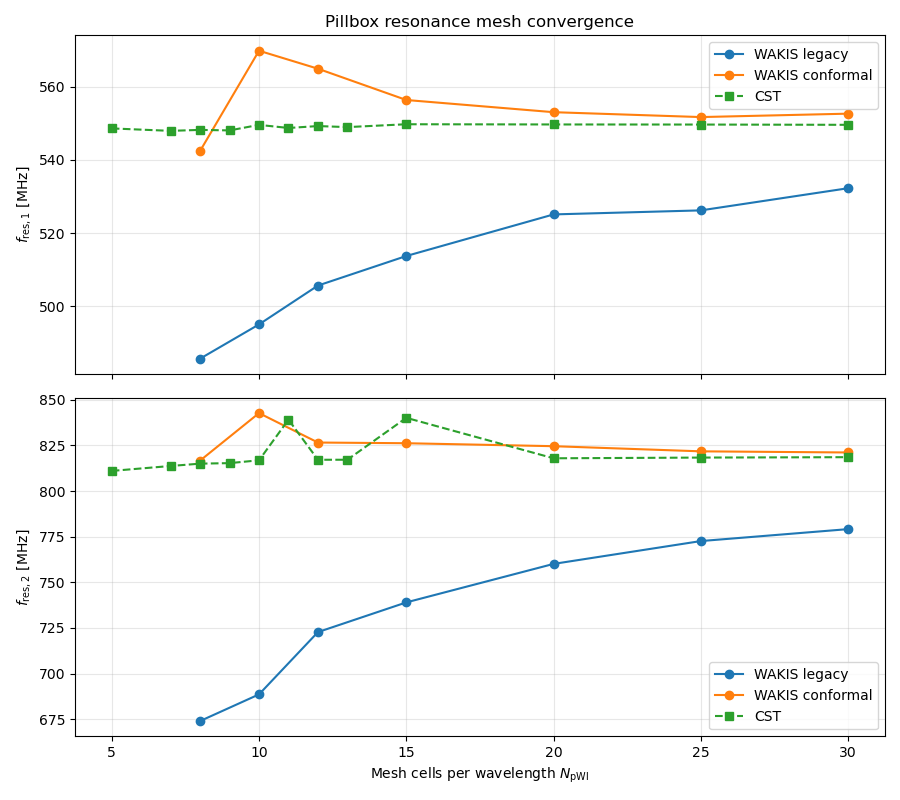

In [26]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(9, 8),
    sharex=True,
)

for mode, label in (
    ("legacy", "WAKIS legacy"),
    ("conformal", "WAKIS conformal"),
):
    npwl = np.asarray(
        [result["requested_npwl"] for result in wakis_results[mode]],
        dtype=float,
    )

    resonances = np.asarray([result["resonances"] for result in wakis_results[mode]])

    axes[0].plot(
        npwl,
        resonances[:, 0] / 1e6,
        marker="o",
        label=label,
    )

    axes[1].plot(
        npwl,
        resonances[:, 1] / 1e6,
        marker="o",
        label=label,
    )

if cst_results:
    cst_npwl = np.asarray(
        [result["requested_npwl"] for result in cst_results],
        dtype=float,
    )

    cst_resonances = np.asarray([result["resonances"] for result in cst_results])

    axes[0].plot(
        cst_npwl,
        cst_resonances[:, 0] / 1e6,
        marker="s",
        linestyle="--",
        label="CST",
    )

    axes[1].plot(
        cst_npwl,
        cst_resonances[:, 1] / 1e6,
        marker="s",
        linestyle="--",
        label="CST",
    )

axes[0].set_ylabel(r"$f_{\mathrm{res},1}$ [MHz]")
axes[1].set_ylabel(r"$f_{\mathrm{res},2}$ [MHz]")
axes[1].set_xlabel(r"Mesh cells per wavelength $N_{\mathrm{pWl}}$")
axes[0].set_title("Pillbox resonance mesh convergence")

for axis in axes:
    axis.grid(True, alpha=0.3)
    axis.legend()

fig.tight_layout()
plt.show()

## Frequency-resolution diagnostic

The impedance sampling used for peak localization is printed below. Note that a dense
post-processing frequency grid does not create information that is absent from the
finite wake length. With `wakelength = 100 m`, the characteristic raw spectral
resolution is of order

\[
\Delta f \sim \frac{c}{L_\mathrm{wake}} \approx 3\,\mathrm{MHz}.
\]

If the finest-mesh convergence becomes comparable to this scale, the wake length should
be increased before interpreting smaller frequency shifts.


In [12]:
print(
    "Characteristic wake-length frequency resolution:",
    f"{c / wakelength / 1e6:.3f} MHz",
)

if wakis_results["legacy"]:
    f = wakis_results["legacy"][-1]["frequency"]

    print(
        "Stored impedance plotting grid spacing:",
        f"{np.median(np.diff(f)) / 1e6:.6f} MHz",
    )

Characteristic wake-length frequency resolution: 2.998 MHz
Stored impedance plotting grid spacing: 0.249975 MHz
